In [1]:
import io, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Upload the DSE historical data CSV.")
df_raw = pd.read_csv(io.BytesIO(uploaded[csv_files[0]]))
print("Raw shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())

Saving DSE_Data.csv to DSE_Data (1).csv
Raw shape: (1523921, 7)
Columns: ['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']


,Trading_Code,Date,Open,High,Low,Close,Volume
0,SIBL,2025-04-08,9.9,10.0,9.8,9.9,359773.0
1,MEGHNALIFE,2025-04-08,54.5,56.6,54.1,56.1,610711.0
2,BPML,2025-04-08,41.1,41.7,40.0,40.2,482031.0
3,CROWNCEMNT,2025-04-08,47.9,50.9,47.5,50.0,104860.0
4,ATCSLGF,2025-04-08,0.0,0.0,0.0,7.5,0.0


In [2]:
def norm(s):
    return re.sub(r"[^a-z0-9]+", "", str(s).strip().lower())

aliases = {
    "tradingcode": ["tradingcode", "ticker", "symbol", "stock"],
    "date": ["date", "tradingdate"],
    "open": ["open", "openingprice"],
    "high": ["high", "highestprice"],
    "low": ["low", "lowestprice"],
    "close": ["close", "closingprice", "ltp"],
    "volume": ["volume", "tradedvolume", "totalvolume"]
}
available = {norm(c): c for c in df_raw.columns}
mapping = {}
for standard, choices in aliases.items():
    for choice in choices:
        if choice in available:
            mapping[available[choice]] = standard
            break

df = df_raw.rename(columns=mapping).copy()
required = ["tradingcode", "date", "open", "high", "low", "close", "volume"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns {missing}. Actual columns: {df_raw.columns.tolist()}. Edit mapping to match your CSV.")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
for c in ["open", "high", "low", "close", "volume"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
before = len(df)
df = df.dropna(subset=["tradingcode", "date", "close"])
df = df.drop_duplicates(subset=["tradingcode", "date"], keep="last")
df = df[(df["close"] > 0) & (df["open"] > 0) & (df["high"] > 0) & (df["low"] > 0)]
df = df[df["high"] >= df["low"]]
df = df.sort_values(["tradingcode", "date"]).reset_index(drop=True)
print("Rows before:", before, "| Rows after:", len(df), "| Removed:", before-len(df))
print("Date range:", df.date.min(), "to", df.date.max())
print("Unique tickers:", df.tradingcode.nunique())
display(df.head())

Rows before: 1523921 | Rows after: 1433177 | Removed: 90744
Date range: 1999-01-02 00:00:00 to 2025-04-08 00:00:00
Unique tickers: 525


,tradingcode,date,open,high,low,close,volume
0,1JANATAMF,2010-01-11,10.6,10.8,10.4,10.5,794000.0
1,1JANATAMF,2010-01-12,10.1,10.3,10.0,10.1,772000.0
2,1JANATAMF,2010-02-11,10.7,10.7,10.3,10.4,781500.0
3,1JANATAMF,2010-02-12,10.1,10.2,9.9,9.9,808500.0
4,1JANATAMF,2010-03-10,12.4,12.5,11.8,11.8,1189500.0


In [3]:
selected = df["tradingcode"].value_counts().head(50).index
df = df[df["tradingcode"].isin(selected)].copy()
df = df.sort_values(["tradingcode", "date"]).reset_index(drop=True)
g = df.groupby("tradingcode", group_keys=False)
df["return_1d"] = g["close"].pct_change()
df["return_5d"] = g["close"].pct_change(5)
df["return_20d"] = g["close"].pct_change(20)
df["volatility_5d"] = g["close"].transform(lambda s: s.pct_change().rolling(5, min_periods=5).std())
df["ma5"] = g["close"].transform(lambda s: s.rolling(5, min_periods=5).mean())
df["ma20"] = g["close"].transform(lambda s: s.rolling(20, min_periods=20).mean())
df["close_ma5_ratio"] = df["close"] / df["ma5"] - 1
df["close_ma20_ratio"] = df["close"] / df["ma20"] - 1
df["vol_ma5"] = g["volume"].transform(lambda s: s.rolling(5, min_periods=5).mean())
df["vol_ma20"] = g["volume"].transform(lambda s: s.rolling(20, min_periods=20).mean())
df["volume_ratio_5_20"] = df["vol_ma5"] / df["vol_ma20"].replace(0, np.nan) - 1
df["future_close_5d"] = g["close"].shift(-5)
df["forward_return_5d"] = df["future_close_5d"] / df["close"] - 1
df["target"] = np.select(
    [df["forward_return_5d"] > 0.02, df["forward_return_5d"] < -0.02],
    ["bullish", "bearish"], default="neutral"
)
features = ["return_1d", "return_5d", "return_20d", "volatility_5d",
            "close_ma5_ratio", "close_ma20_ratio", "volume_ratio_5_20"]
model_df = df[["tradingcode", "date", "target"] + features].replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(subset=features + ["target"]).sort_values("date").reset_index(drop=True)
print("Selected tickers:", model_df.tradingcode.nunique())
print("Modeling rows:", len(model_df))
display(model_df.head())
display(model_df["target"].value_counts().to_frame("count"))

Selected tickers: 50
Modeling rows: 297162


,tradingcode,date,target,return_1d,return_5d,return_20d,volatility_5d,close_ma5_ratio,close_ma20_ratio,volume_ratio_5_20
0,ALLTEX,1999-02-10,bullish,-0.056995,-0.180180,-0.183857,0.078286,-0.114786,-0.132093,-0.564160
1,SQURPHARMA,1999-02-10,bullish,-0.048130,-0.116974,-0.119897,0.037357,-0.072912,-0.098784,0.575758
2,ARAMIT,1999-02-10,bullish,0.126615,-0.169524,-0.163148,0.152924,-0.020665,-0.110113,0.487310
3,SINGERBD,1999-02-10,bullish,-0.153926,-0.260127,-0.255665,0.130910,-0.140536,-0.196584,0.654809
4,BDLAMPS,1999-02-10,bullish,-0.139785,-0.208262,-0.217687,0.157491,-0.094845,-0.155808,-0.300236


,count
target,
bearish,111677
bullish,105974
neutral,79511


In [4]:
dates = np.sort(model_df["date"].unique())
cutoff = pd.Timestamp(dates[int(len(dates) * 0.8)])
train = model_df[model_df.date < cutoff].copy()
test = model_df[model_df.date >= cutoff].copy()
X_train, y_train = train[features], train["target"]
X_test, y_test = test[features], test["target"]
print("Cutoff:", cutoff)
print("Train rows:", len(train), "| period:", train.date.min(), "to", train.date.max())
print("Test rows:", len(test), "| period:", test.date.min(), "to", test.date.max())
display(y_train.value_counts(normalize=True).to_frame("train proportion"))
display(y_test.value_counts(normalize=True).to_frame("test proportion"))

Cutoff: 2019-09-30 00:00:00
Train rows: 234786 | period: 1999-02-10 00:00:00 to 2019-09-29 00:00:00
Test rows: 62376 | period: 2019-09-30 00:00:00 to 2025-04-08 00:00:00


,train proportion
target,
bearish,0.390709
bullish,0.380572
neutral,0.228719


,test proportion
target,
neutral,0.413797
bearish,0.319738
bullish,0.266465


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=14, min_samples_leaf=5,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    )
}
results, predictions = [], {}
for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred)
    })
results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
display(results_df.round(4))

Training: Logistic Regression
Training: Random Forest


,Model,Accuracy,Macro F1,Balanced Accuracy
1,Random Forest,0.5750,0.5532,0.5518
0,Logistic Regression,0.5463,0.5299,0.5281



Logistic Regression
              precision    recall  f1-score   support

     bearish       0.56      0.46      0.51     19944
     neutral       0.57      0.68      0.62     25811
     bullish       0.49      0.45      0.47     16621

    accuracy                           0.55     62376
   macro avg       0.54      0.53      0.53     62376
weighted avg       0.54      0.55      0.54     62376



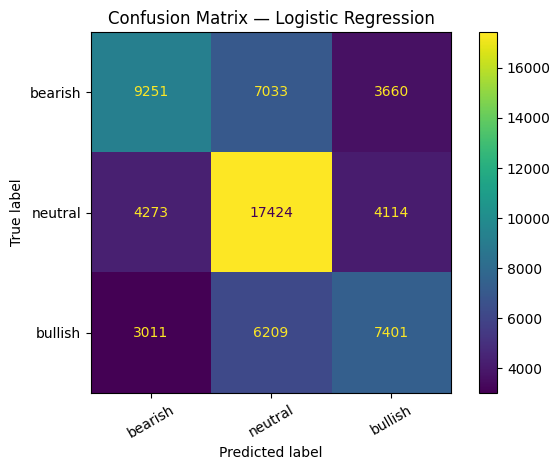


Random Forest
              precision    recall  f1-score   support

     bearish       0.60      0.47      0.53     19944
     neutral       0.60      0.74      0.66     25811
     bullish       0.49      0.44      0.47     16621

    accuracy                           0.57     62376
   macro avg       0.57      0.55      0.55     62376
weighted avg       0.57      0.57      0.57     62376



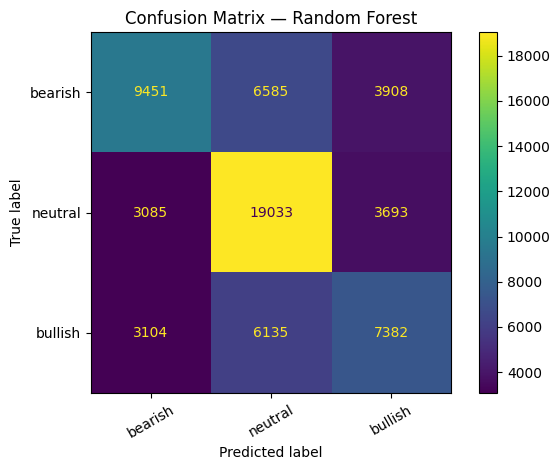

In [6]:
for name, pred in predictions.items():
    print("\n" + "="*50 + "\n" + name)
    print(classification_report(y_test, pred, labels=["bearish", "neutral", "bullish"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=["bearish", "neutral", "bullish"],
        display_labels=["bearish", "neutral", "bullish"], xticks_rotation=30
    )
    plt.title("Confusion Matrix — " + name)
    plt.tight_layout()
    plt.show()

## 6. Findings and what I would change with more time

After running the notebook, replace the bracketed prompts with your actual results. Do not invent metric values.

1. The experiment used [number] observations from [number] selected DSE trading codes after cleaning and feature engineering.
2. The chronological test period began on [cutoff date], so evaluation used later dates than training.
3. Logistic Regression achieved an accuracy of [value] and macro F1-score of [value].
4. Random Forest achieved an accuracy of [value] and macro F1-score of [value]; the better model by macro F1 was [model name].
5. The confusion matrices show that [describe which classes were easiest or hardest to classify from the results].
6. With more time, I would test more tickers, use walk-forward validation, compare different horizons and thresholds, and include transaction costs before drawing conclusions about trading usefulness.
